In [1]:
import pandas as pd
import yaml
import re
import os
import numpy as np
import matplotlib.pylab as plt
import matplotlib
import csv
# from labellines import labelLine, labelLines
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cantera as ct
%matplotlib inline

In [2]:
font = {
    # 'family' : 'normal',
        'weight' : 'bold',
        'size'   : 12}

matplotlib.rc('font', **font)
matplotlib.rc('lines', linewidth=1.8, color='black')

fontdict={
    #'family' : 'normal',
        'weight' : 'bold',
        'size'   : 12}

# Blend Plots 

In [15]:
# gathered some statistics on the final models 
        
PMS = ['R290_R152a',
      'R50_R152a', 
      'R600a_R152a', 
      'R600a_R32']
                


MS = ['R290_R134a',
     'R290_R32', 
      'R50_R134a', 
      'R50_R32', 
        'R600a_R134a', 
     ]


                      #concatenated models      #pure models        #MS blend models   #PMS blend models 
path_directories = ['./concatenated_blends', './single_component', './MS_blends', './PMS_blends'] #change this to the directories that are appropriate
model_names = ['concatenated', 'pure', 'MS', 'PMS'] 

for model_name, path_ in zip(model_names, path_directories): 
    blends = [blend for blend in os.listdir(path_) if 'R' in blend]
    for blend in blends: 


        
        final_model_chemkin = [chem for chem in os.listdir(f'{path_to_use}/{blend}/chemkin') if 'final_model' in chem][0] #identify the model size that you will be using as the final model and then add this string to the name of the .yaml

        gas = ct.Solution(f'{path_to_use}/{blend}/chemkin/{final_model_chemkin}')
        print(model_name, blend, len(gas.reactions()), len(gas.species()))
    

concatenated R290_R134a 5527 210
concatenated R290_R152a 4452 171
concatenated R290_R32 6918 258
concatenated R50_R134a 4500 213
concatenated R50_R152a 3425 174
concatenated R50_R32 5891 261
concatenated R600a_R134a 6335 234
concatenated R600a_R152a 5249 194
concatenated R600a_R32 7769 287
pure R134a 1542 88
pure R152a 473 49
pure R290 4061 141
pure R32 3068 149
pure R50 3034 144
pure R600a 4858 164
MS R290_R134a 2110 119
MS R290_R152a 3807 149
MS R290_R32 4639 163
MS R50_R134a 3972 149
MS R50_R152a 1261 174
MS R50_R32 3713 143
MS R600a_R134a 1154 97
MS R600a_R152a 1200 79
MS R600a_R32 1164 97


# FINAL BLENDS PLOT

new R134a
MS blend not completed speeds: R290_R134a
MS blend not completed speeds: R290_R32
new R134a
MS blend not completed speeds: R50_R134a
MS blend not completed speeds: R50_R152a
MS blend not completed speeds: R50_R32
new R134a
[1.324653469863277, 2.300499476696546, 3.627063402363098, 5.215030863021898, 6.963008774731142, 8.7182773531408, 10.274386550131991, 11.40404491207963, 11.854286825648131, 11.46933892915844, 10.176425984130729, 8.425114648779598, 6.657280994864648, 5.084129225391786, 3.8610383142994578, 3.0145749785535423, 2.375081478462318, 1.934036588140223, 1.6239458656232422, 1.402301175455372, 1.236092660771046, 1.116073819692285, 1.023036569889736, 0.9503872648753395, 0.8853140500088763, 0.8336430556577986, 0.787406444772546, 0.745778583670253, 0.7097593177560914, 0.6761146046354443, 0.6429313465191446, 0.6111345750910893, 0.5816737873338904, 0.5541281825254818, 0.5282607798062359, 0.5029558207914904, 0.47659791504485305, 0.4551268714943267, 0.4352528891912816, 0.4173

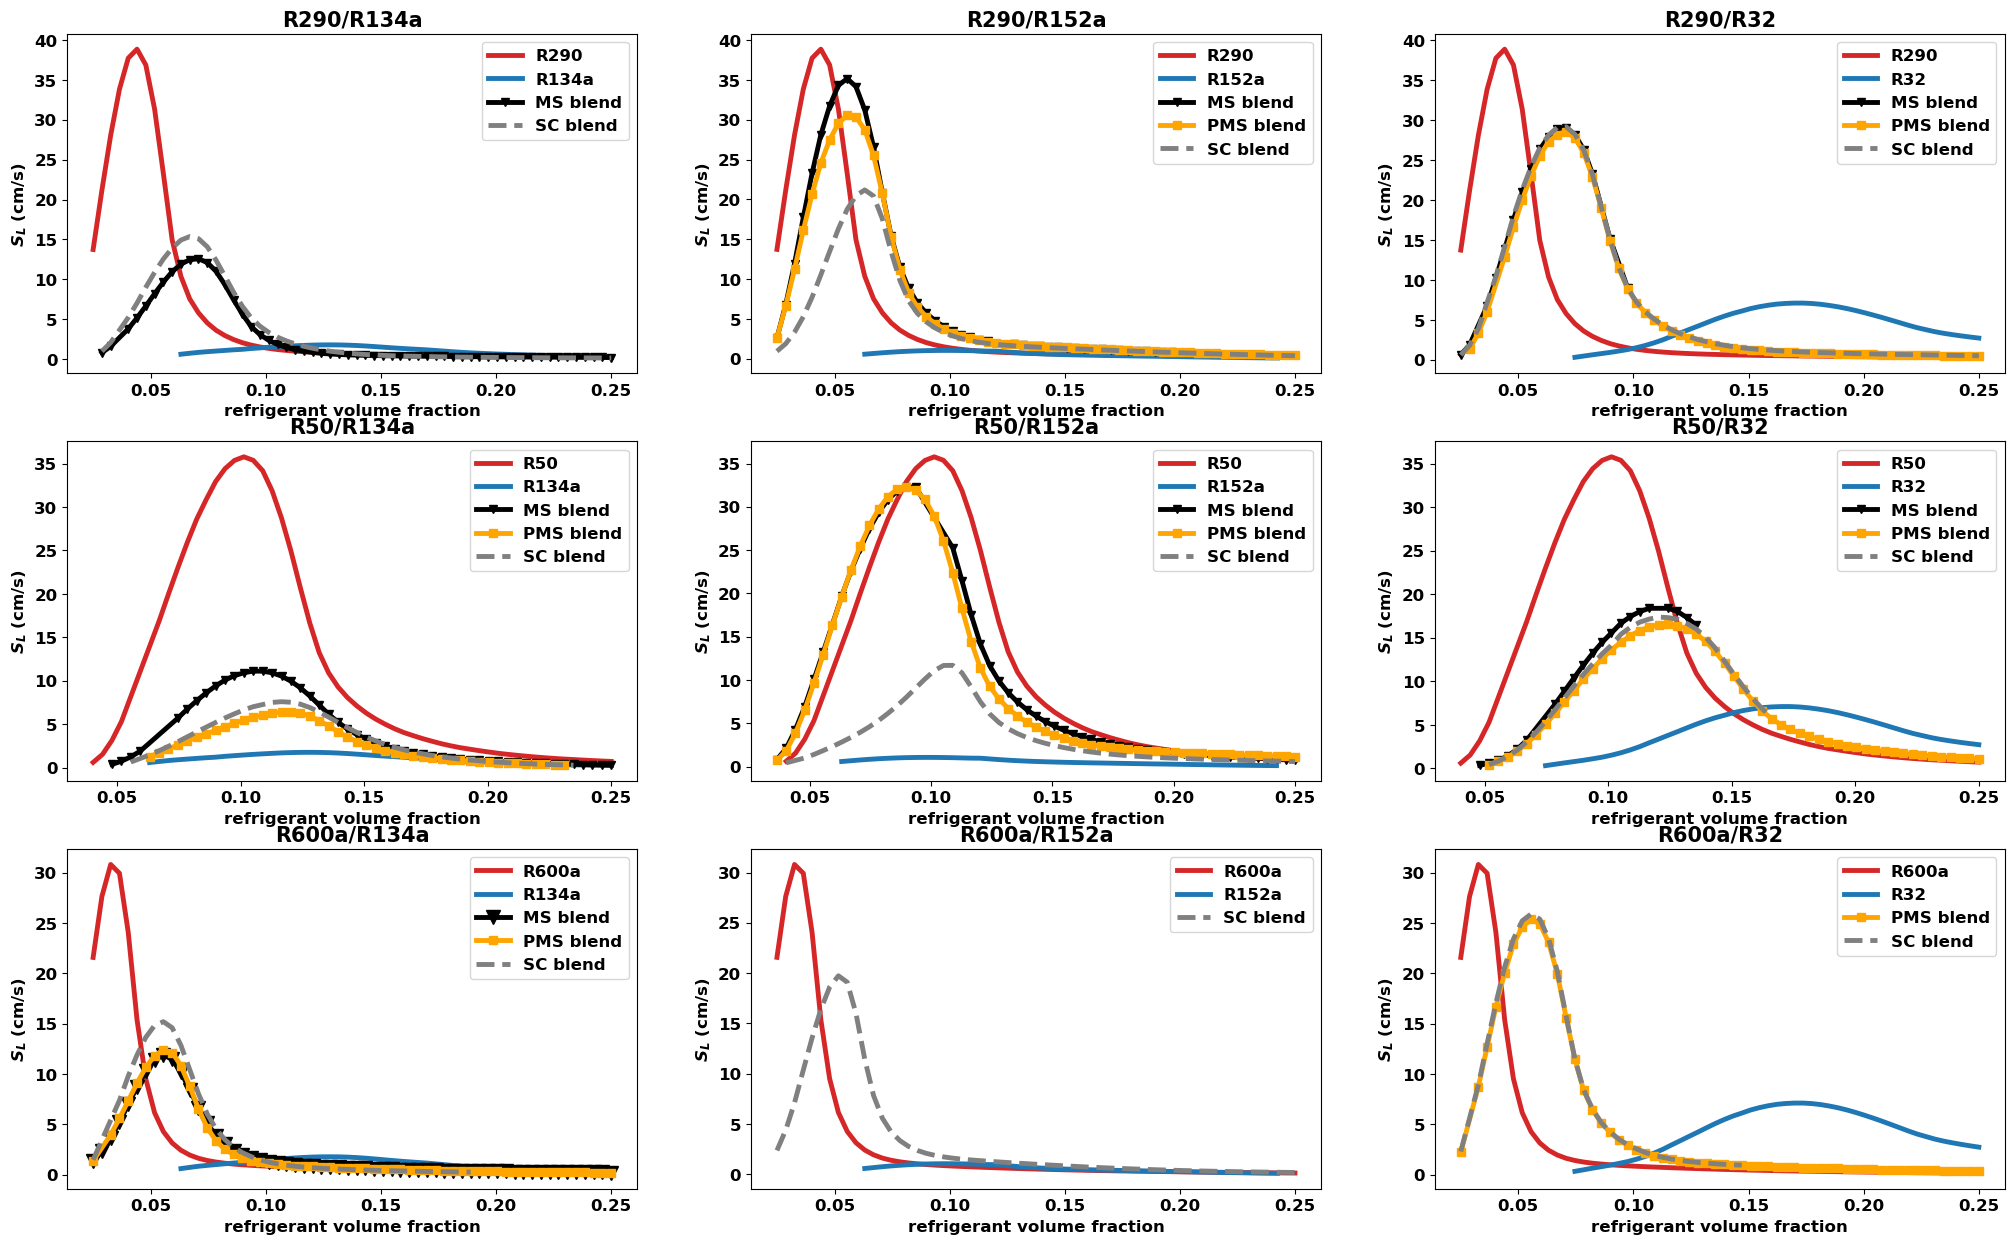

In [5]:
#run this second to plot the blends
#taken from: changing_RMG_Py/on_USNCM_blends/
plt.rcParams['figure.figsize'] = [25, 15] 

single_colors = ['tab:red', 'tab:blue']

blends = [folder for folder in os.listdir('./blends/') if 'R' in folder] #just name a directory with all the binary blend names

#for overall plot 
num_cols = 3
num_rows = 3
fig, axs = plt.subplots(num_rows, num_cols)


max_flamespeeds_blend = {} #keys = blend_name, values = (MS, conc)


count = 0 #for keeping track of where we are in the plot 
for index, blend in enumerate(blends): 

    single_components = blend.split('_') #identify the single components
    
    #figure out where the subplot will go in the larger big plot
    row_divisor = count//num_cols 
    row_remainder = count%num_cols
    axes_pair = [row_divisor, row_remainder] #if there is a remainder
        
        
    ################ singles data ########################
    for single_comp, color in zip(single_components, single_colors): 


        full_path = f'./single_component/{single_comp}/speeds/' #I have a folder that has all the flame speed data that Cantera solved for.

        # NOTE: we are parsing the yamls instead of using yaml.safeload() or yaml.load(). Loading in the yamls takes FOREVER. 

        yamls = [file for file in os.listdir(full_path) if 'yaml' in file]
        vol_fracs = []
        speeds = []
        for yaml_ in yamls: 
            vol_frac = re.search('speed_(\S+)\.yaml', yaml_).group(1) #change this search string if needed
            with open(full_path+yaml_, 'r') as f: 
                yaml_data = f.readlines()

            for dataline in yaml_data: 
                if 'velocity:' in dataline: 
                    flamespeed = re.search('velocity\: \[(\S+)\,', dataline).group(1)
                    # print(flamespeed)
            speeds.append(float(flamespeed)*100)
            vol_fracs.append(float(vol_frac))

                
        axs[axes_pair[0], axes_pair[1]].plot(vol_fracs, speeds, '-', c=color, linewidth=3.5, label=single_comp)
          
    
    ################## MS blend data  #############
    if blend in MS: 
        full_path = f'./blends/{blend}/speeds/'
   

        print(f'MS blend not completed speeds: {blend}')
        yamls = [file for file in os.listdir(full_path) if 'yaml' in file]
        vol_fracs = []
        speeds = []
        for yaml_ in yamls: 
            vol_frac = re.search('speed_(\S+)\.yaml', yaml_).group(1)
            with open(full_path+yaml_, 'r') as f: 
                yaml_data = f.readlines()
        
            for dataline in yaml_data: 
                if 'velocity:' in dataline: 
                    flamespeed = re.search('velocity\: \[(\S+)\,', dataline).group(1)
                    # print(flamespeed)
            speeds.append(float(flamespeed)*100)
            vol_fracs.append(float(vol_frac))
               
            
        axs[axes_pair[0], axes_pair[1]].plot(vol_fracs, speeds, '-v',c='black', linewidth=3.5, label='MS blend')
        max_flamespeeds_blend[blend] = (max(speeds), None)

    
    ################# PMS blend data #################
    if blend in MS_mistakenly: 
        full_path = f'./PMS'

        yamls = [file for file in os.listdir(full_path) if 'yaml' in file]
        vol_fracs = []
        speeds = []
        for yaml_ in yamls: 
            vol_frac = re.search('speed_(\S+)\.yaml', yaml_).group(1)
            with open(full_path+yaml_, 'r') as f: 
                yaml_data = f.readlines()
        
            for dataline in yaml_data: 
                if 'velocity:' in dataline: 
                    flamespeed = re.search('velocity\: \[(\S+)\,', dataline).group(1)
                    # print(flamespeed)
            speeds.append(float(flamespeed)*100)
            vol_fracs.append(float(vol_frac))

        axs[axes_pair[0], axes_pair[1]].plot(vol_fracs, speeds, '-v',c='black', linewidth=3.5, label='MS blend')


        if yamls==[]: #if no yamls, look at output logs

            frac_speed_dict = {}
            output_logs = [file for file in os.listdir(full_path) if 'fc_all.' in file]
            for log in output_logs:
                #print(log)
                with open(full_path+log, 'r') as f: 
                    log_data = f.readlines() 

                vol_frac=None
                flamespeed=None
                for line in log_data: 
                    if 'total volume fraction: ' in line: 
                        vol_frac = float(re.search('total volume fraction\: (\S+)', line).group(1))
                    if 'flamespeed = ' in line: 
                        flamespeed = float(re.search('flamespeed = (\S+)', line).group(1))*100
                if vol_frac!=None and flamespeed!=None: 
                    frac_speed_dict[vol_frac] = flamespeed
                    
            axs[axes_pair[0], axes_pair[1]].plot([tup[0] for tup in sorted(frac_speed_dict.items())],[tup[1] for tup in sorted(frac_speed_dict.items())], '-s',c='orange', linewidth=3.5, label='PMS blend')
            
    

################# repeat for any blend methods you need #################
    

    

    
    count+=1
        
    axs[axes_pair[0], axes_pair[1]].set_xlabel('refrigerant volume fraction',fontweight='bold')
    axs[axes_pair[0], axes_pair[1]].set_ylabel(r'$S_{L}$ (cm/s)',fontdict=fontdict)
    axs[axes_pair[0], axes_pair[1]].set_title(blend.replace('_','/'), fontsize = 15, fontweight='bold')
    axs[axes_pair[0], axes_pair[1]].legend()       
        

#fig.savefig('./blends_plot.pdf')